# Revised Experiment 194 · Does redundancy predict replay value?

**Complete** · Revised Experiment 194 results saved · ETA 0h 00m 00s

At each Phase A origin, the ordered and shuffled windows start from the same model and optimizer state and contain the same images. Each order uses a shared 64-arrival prefix at 25% and then branches into 12.5%, 25%, and 37.5% for 704 arrivals. A common 768-arrival continuation uses fixed 25%. Fresh masks are paired by arrival. Current and historical reconstruction MSE are measured every 256 arrivals. Phase A also records prefix-gradient cosine, shift status, and the age and regime mix of sampled history.

Phase B freezes the redundancy-to-value mapping using development seeds only. The score is past-prefix pixel redundancy and targets the expected value of adding 12.5 percentage points of replay. The controller uses a deadband and at most two upward and two downward changes per regime, with a feasible exact replay quota. Inverse flips the requested move, and random balances two moves in each direction with four neutral windows. Contrasts use both counterbalanced versions, paired masks and held-out model seeds. The constant-rate references were selected on development runs by current and historical MSE. Each reference uses one update per arrival at its own replay rate.

Matched branch cases · 48. Rate screen runs · 24. Deployment runs · 60. On-policy audit cases · 24.

## A · Is extra replay worth more in ordered windows?

Positive values mean the 37.5% versus 12.5% advantage was larger in ordered windows. Intervals pair by seed.

| Seeds | Readouts | Matched cases | Current MSE contrast [95% CI] | Historical MSE contrast [95% CI] |
| --- | --- | --- | --- | --- |
 | development | intervention | 12 | +0.02438 [-0.00718, +0.05594] | +0.00743 [-0.00454, +0.01941] | 
 | development | continuation | 12 | +0.00247 [-0.00287, +0.00782] | +0.00283 [-0.00618, +0.01184] | 
 | development | combined | 12 | +0.01343 [-0.00076, +0.02762] | +0.00513 [+0.00167, +0.00859] | 
 | held-out | intervention | 12 | +0.01942 [-0.01791, +0.05674] | +0.01117 [-0.00354, +0.02589] | 
 | held-out | continuation | 12 | -0.00268 [-0.00988, +0.00451] | -0.00198 [-0.01575, +0.01179] | 
 | held-out | combined | 12 | +0.00837 [-0.01155, +0.02829] | +0.00460 [-0.00047, +0.00966] | 

| Held-out window | Readouts | Rate | Current gain vs 25% [95% CI] | Historical gain vs 25% [95% CI] |
| --- | --- | --- | --- | --- |
 | clip | intervention | 12.5% | -0.00851 [-0.03420, +0.01717] | -0.02600 [-0.07758, +0.02559] | 
 | clip | intervention | 37.5% | +0.00879 [-0.01743, +0.03501] | +0.01647 [-0.02320, +0.05614] | 
 | clip | continuation | 12.5% | +0.00242 [-0.00333, +0.00818] | -0.01057 [-0.05785, +0.03670] | 
 | clip | continuation | 37.5% | +0.00095 [-0.00144, +0.00335] | +0.00299 [-0.00970, +0.01568] | 
 | shuffled | intervention | 12.5% | +0.00112 [-0.00963, +0.01187] | -0.01871 [-0.06839, +0.03098] | 
 | shuffled | intervention | 37.5% | -0.00099 [-0.00923, +0.00725] | +0.01259 [-0.02453, +0.04970] | 
 | shuffled | continuation | 12.5% | -0.00078 [-0.00396, +0.00239] | -0.01076 [-0.04724, +0.02571] | 
 | shuffled | continuation | 37.5% | +0.00043 [-0.00078, +0.00164] | +0.00478 [-0.00917, +0.01874] | 

## Development fixed-rate screen

| Fixed rate | Runs | Current MSE | Historical MSE |
| --- | --- | --- | --- |
 | 12.5% | 6 | 0.91077 | 0.87956 | 
 | 25% | 6 | 0.90909 | 0.85222 | 
 | 37.5% | 6 | 0.90723 | 0.84266 | 
 | 50% | 6 | 0.90606 | 0.83689 | 

The frozen policy’s development marginal slope per unit of redundancy is +0.00546 MSE. The selected rates are 50% for current MSE and 50% for historical MSE.

On 24 held-out branches, the marginal-value RMSE is 0.00861 for the causal signal and 0.00855 for the constant development mean. Sign agreement around that mean is 66.7%.

## B · Prospective held-out learning trajectories

| Policy | Rollouts | Current MSE | Historical MSE | Forgetting +256 | Forgetting +768 | Replay updates | Train + data (s) | Controller (s) |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
 | fixed 25% | 12 | 0.88731 | 0.86556 | -0.01886 | -0.01569 | 4,608 | 145.19 | 0.000 | 
 | correlation-aware | 12 | 0.88543 | 0.86591 | -0.01729 | -0.01604 | 4,608 | 145.65 | 0.074 | 
 | inverse | 12 | 0.88917 | 0.86956 | -0.01687 | -0.00796 | 4,608 | 145.26 | 0.072 | 
 | random balanced | 12 | 0.88818 | 0.86756 | -0.01683 | -0.00924 | 4,608 | 146.09 | 0.002 | 
 | fixed 50% | 12 | 0.87592 | 0.84927 | -0.03201 | -0.03335 | 9,216 | 146.80 | 0.000 | 

| Comparator | Current MSE gain [95% CI] | Historical MSE gain [95% CI] |
| --- | --- | --- |
 | fixed 25% | +0.00187 [+0.00118, +0.00256] | -0.00034 [-0.00169, +0.00100] | 
 | inverse | +0.00374 [+0.00227, +0.00520] | +0.00366 [+0.00328, +0.00403] | 
 | random balanced | +0.00274 [+0.00138, +0.00411] | +0.00165 [-0.00223, +0.00554] | 
 | fixed 50% | -0.00951 [-0.00997, -0.00906] | -0.01664 [-0.01983, -0.01345] | 

| Policy | Clip-ordered replay | Shuffled replay | Windows with a non-25% rate |
| --- | --- | --- | --- |
 | fixed 25% | 25.0% | 25.0% | 0.0% | 
 | correlation-aware | 29.3% | 20.7% | 45.8% | 
 | inverse | 20.7% | 29.3% | 45.8% | 
 | random balanced | 25.0% | 25.0% | 50.0% | 
 | fixed 50% | 50.0% | 50.0% | 100.0% | 

The held-out primary success criterion was unmet. It requires paired 95% intervals above zero for both MSE gains against 25%.

## C · Failure diagnostics

| Features | Held-out marginal-value RMSE | Centered sign agreement |
| --- | --- | --- |
 | redundancy | 0.00861 | 66.7% | 
 | redundancy + memory | 0.00693 | 83.3% | 
 | redundancy + memory + shift + gradient | 0.00664 | 75.0% | 

| Readouts | Locally selected gain [95% CI] |
| --- | --- |
 | intervention | +0.00098 [-0.01663, +0.01859] | 
 | continuation | -0.00190 [-0.01040, +0.00661] | 
 | combined | -0.00046 [-0.01312, +0.01220] | 

The visit-state audit compares the causal policy’s choice and the hindsight oracle with 25% from each starting state. Both use the same windows and fresh masks.

| Origin | Readouts | Sites | Selected gain [95% CI] | Oracle gain [95% CI] |
| --- | --- | --- | --- | --- |
 | fixed 25% | intervention | 12 | +0.00183 [-0.00010, +0.00376] | +0.00395 [+0.00245, +0.00545] | 
 | fixed 25% | continuation | 12 | +0.00009 [-0.00021, +0.00040] | +0.00078 [-0.00007, +0.00162] | 
 | fixed 25% | combined | 12 | +0.00096 [-0.00013, +0.00205] | +0.00235 [+0.00194, +0.00276] | 
 | correlation-aware | intervention | 12 | +0.00222 [+0.00079, +0.00365] | +0.00445 [+0.00233, +0.00658] | 
 | correlation-aware | continuation | 12 | +0.00033 [-0.00008, +0.00075] | +0.00090 [+0.00034, +0.00146] | 
 | correlation-aware | combined | 12 | +0.00128 [+0.00058, +0.00197] | +0.00264 [+0.00195, +0.00333] | 

## External frozen probes

| Policy | Runs | Scene | Weather | Lighting | Pedestrian |
| --- | --- | --- | --- | --- | --- |
 | fixed 25% | 12 | 42.8% | 44.5% | 96.2% | 58.2% | 
 | correlation-aware | 12 | 43.6% | 44.9% | 95.9% | 58.4% | 
 | inverse | 12 | 43.3% | 45.0% | 96.1% | 58.4% | 
 | random balanced | 12 | 42.1% | 44.6% | 96.2% | 58.4% | 
 | fixed 50% | 12 | 43.4% | 45.6% | 96.4% | 58.5% | 



In [ ]:
# Run this cell to watch the background worker. Interrupt it to stop watching.
from IPython.display import Image, Markdown, clear_output, display
from pathlib import Path
import base64, json, time

run = Path('C:\\CAFL-E\\analysis\\2026-11-09-one-step-mpc\\o3-correlation-value')
while True:
    try:
        status = json.loads((run / 'status.json').read_text(encoding='utf-8'))
        cells = json.loads((run / 'progress.ipynb').read_text(encoding='utf-8'))['cells']
    except (FileNotFoundError, PermissionError):
        time.sleep(1)
        continue
    clear_output(wait=True)
    for cell in cells:
        if cell['cell_type'] == 'markdown':
            display(Markdown(''.join(cell['source'])))
        for output in cell.get('outputs', []):
            if png := output.get('data', {}).get('image/png'):
                display(Image(data=base64.b64decode(png)))
    if status['state'] in ('complete', 'stopped', 'failed'):
        break
    time.sleep(10)


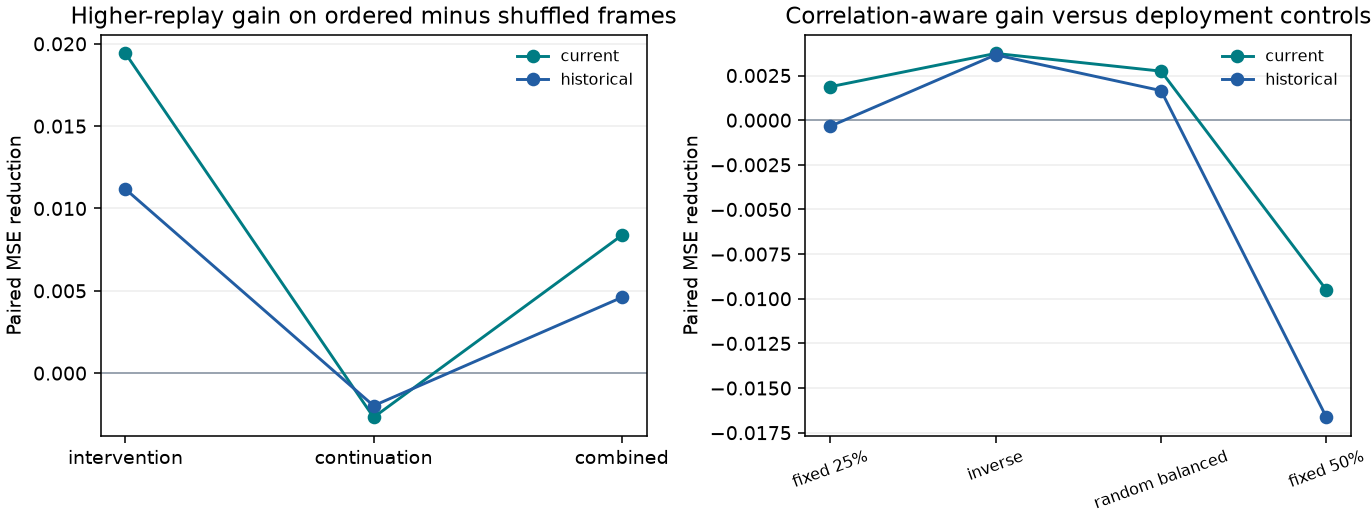